In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [42]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

In [45]:
from scipy.stats import spearmanr

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

In [44]:
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.base import clone
from sklearn.inspection import permutation_importance

In [2]:
df = pd.read_csv("dataset/StressLevelDataset.csv")
print("Dataset shape:", df.shape)
print(df.head())

Dataset shape: (1100, 21)
   anxiety_level  self_esteem  mental_health_history  depression  headache  \
0             14           20                      0          11         2   
1             15            8                      1          15         5   
2             12           18                      1          14         2   
3             16           12                      1          15         4   
4             16           28                      0           7         2   

   blood_pressure  sleep_quality  breathing_problem  noise_level  \
0               1              2                  4            2   
1               3              1                  4            3   
2               1              2                  2            2   
3               3              1                  3            4   
4               3              5                  1            3   

   living_conditions  ...  basic_needs  academic_performance  study_load  \
0                  3

In [3]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  study_load                    1100 non-null 

In [4]:
df.describe()

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
count,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,...,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000,1100.000000
mean,11.063636,17.777273,0.492727,12.555455,2.508182,2.181818,2.660000,2.753636,2.649091,2.518182,...,2.772727,2.772727,2.621818,2.648182,2.649091,1.881818,2.734545,2.767273,2.617273,0.996364
std,6.117558,8.944599,0.500175,7.727008,1.409356,0.833575,1.548383,1.400713,1.328127,1.119208,...,1.433761,1.414594,1.315781,1.384579,1.529375,1.047826,1.425265,1.417562,1.530958,0.821673
min,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.000000,11.000000,0.000000,6.000000,1.000000,1.000000,1.000000,2.000000,2.000000,2.000000,...,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,2.000000,2.000000,1.000000,0.000000
50%,11.000000,19.000000,0.000000,12.000000,3.000000,2.000000,2.500000,3.000000,3.000000,2.000000,...,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.500000,3.000000,1.000000
75%,16.000000,26.000000,1.000000,19.000000,3.000000,3.000000,4.000000,4.000000,3.000000,3.000000,...,4.000000,4.000000,3.000000,4.000000,4.000000,3.000000,4.000000,4.000000,4.000000,2.000000
max,21.000000,30.000000,1.000000,27.000000,5.000000,3.000000,5.000000,5.000000,5.000000,5.000000,...,5.000000,5.000000,5.000000,5.000000,5.000000,3.000000,5.000000,5.000000,5.000000,2.000000


In [5]:
print(df.isnull().sum())
print(df["stress_level"].value_counts())

anxiety_level                   0
self_esteem                     0
mental_health_history           0
depression                      0
headache                        0
blood_pressure                  0
sleep_quality                   0
breathing_problem               0
noise_level                     0
living_conditions               0
safety                          0
basic_needs                     0
academic_performance            0
study_load                      0
teacher_student_relationship    0
future_career_concerns          0
social_support                  0
peer_pressure                   0
extracurricular_activities      0
bullying                        0
stress_level                    0
dtype: int64
stress_level
0    373
2    369
1    358
Name: count, dtype: int64


In [6]:
df = df.copy()

In [7]:
df.columns = df.columns.str.strip()

In [8]:
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
print("Text columns:", text_cols)

Text columns: []


In [9]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [10]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [20]:
print("stress_level values:", sorted(df["stress_level"].unique()))
print("Negative values:", (df < 0).sum().sum())

stress_level values: [np.int64(0), np.int64(1), np.int64(2)]
Negative values: 0


In [11]:
ranges = pd.DataFrame({
    "Min": df.min(),
    "Max": df.max(),
    "Unique Values": df.nunique()
})
print(ranges)

                              Min  Max  Unique Values
anxiety_level                   0   21             22
self_esteem                     0   30             31
mental_health_history           0    1              2
depression                      0   27             28
headache                        0    5              6
blood_pressure                  1    3              3
sleep_quality                   0    5              6
breathing_problem               0    5              6
noise_level                     0    5              6
living_conditions               0    5              6
safety                          0    5              6
basic_needs                     0    5              6
academic_performance            0    5              6
study_load                      0    5              6
teacher_student_relationship    0    5              6
future_career_concerns          0    5              6
social_support                  0    3              4
peer_pressure               

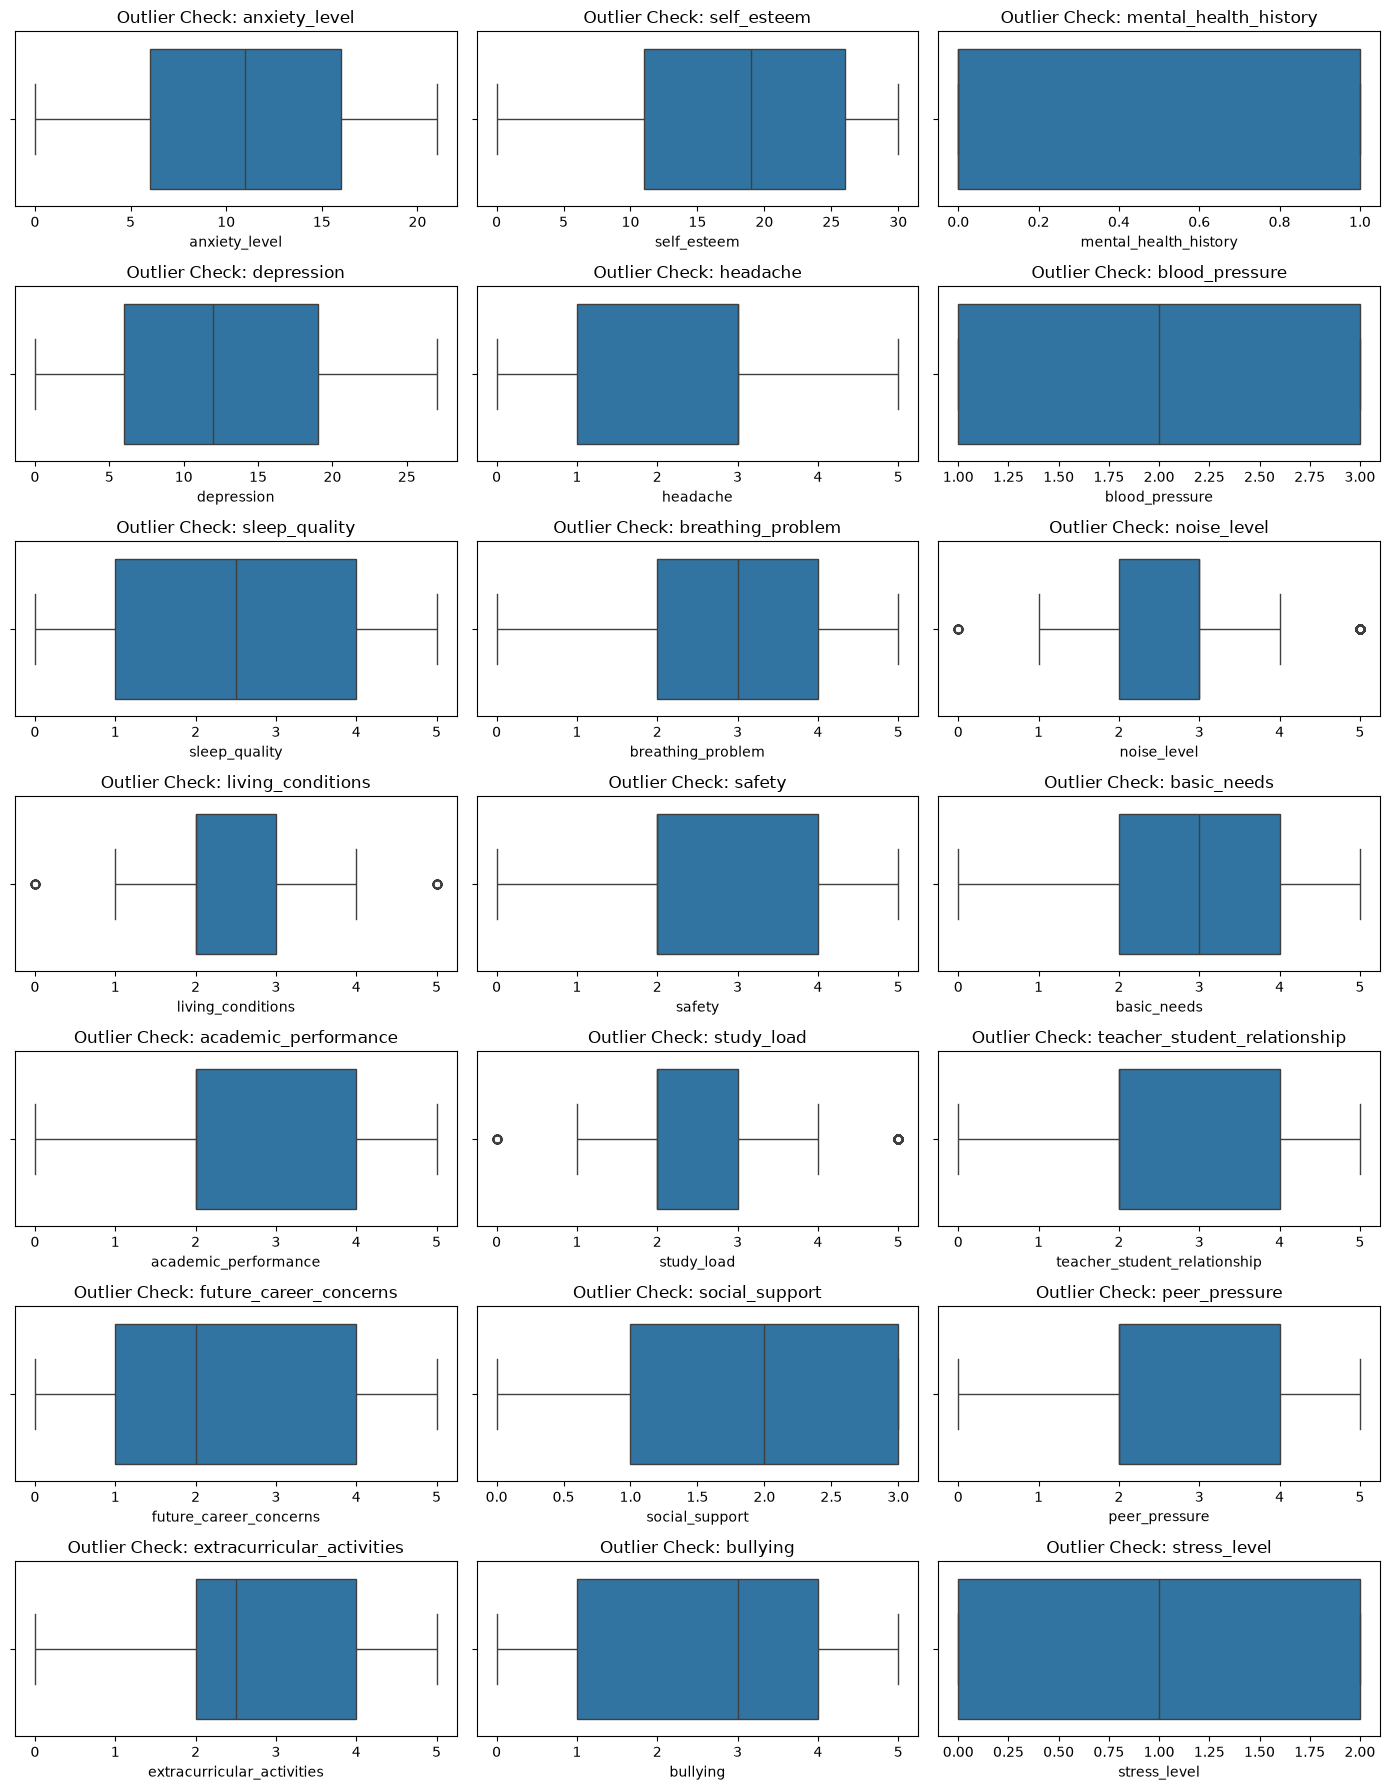

In [13]:
num_cols = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
fig, axes = plt.subplots(7, 3, figsize=(14, 18))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title("Outlier Check: " + col)
plt.tight_layout()
plt.show()

In [14]:
outlier_results = []
for col in num_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (
        (df[col] < lower) |
        (df[col] > upper)
    ).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df[outlier_df["Flagged Values"] > 0].to_string(index=False))

           Column  Lower Bound  Upper Bound  Flagged Values
      noise_level          0.5          4.5             173
living_conditions          0.5          4.5              62
       study_load          0.5          4.5             165


only noise_level, study_load and living_conditions are flagged. These are answers on a 0 to 5 scale, so the flagged values are valid survey answers and not errors. No rows were removed.

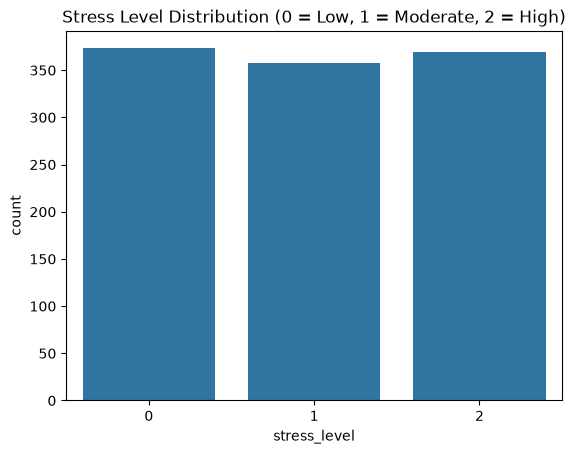

In [15]:
sns.countplot(x="stress_level", data=df)
plt.title("Stress Level Distribution (0 = Low, 1 = Moderate, 2 = High)")
plt.show()

In [16]:
print((df["stress_level"].value_counts(normalize=True) * 100).round(2))

stress_level
0    33.91
2    33.55
1    32.55
Name: proportion, dtype: float64


In [17]:
print("NaN in correlation:", df.corr().isnull().sum().sum())

NaN in correlation: 0


C:\Users\Bhoomi\AppData\Local\Temp\ipykernel_8336\1952642189.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=corr.values, y=corr.index, palette="coolwarm")


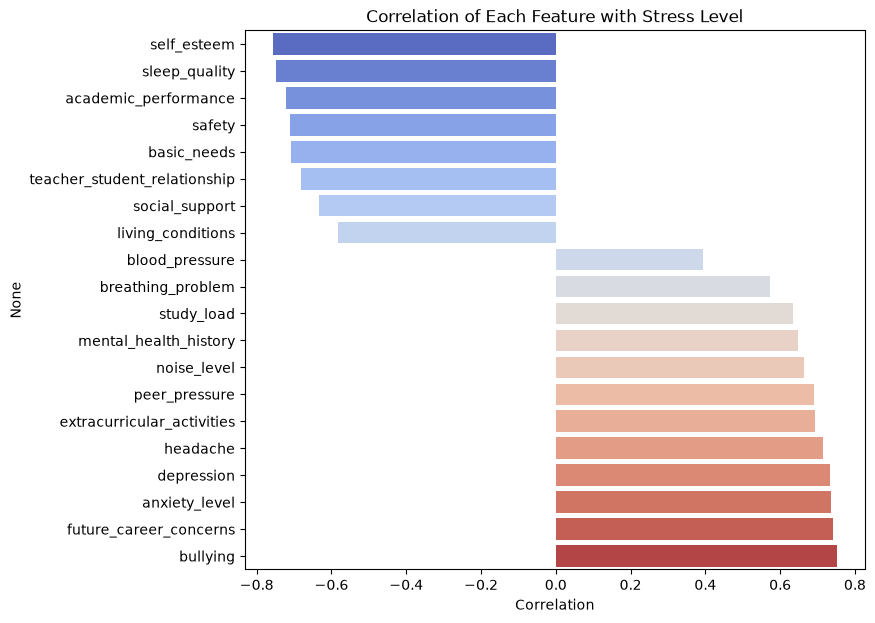

In [18]:
corr = df.corr()["stress_level"].drop("stress_level").sort_values()
plt.figure(figsize=(8, 7))
sns.barplot(x=corr.values, y=corr.index, palette="coolwarm")
plt.title("Correlation of Each Feature with Stress Level")
plt.xlabel("Correlation")
plt.show()

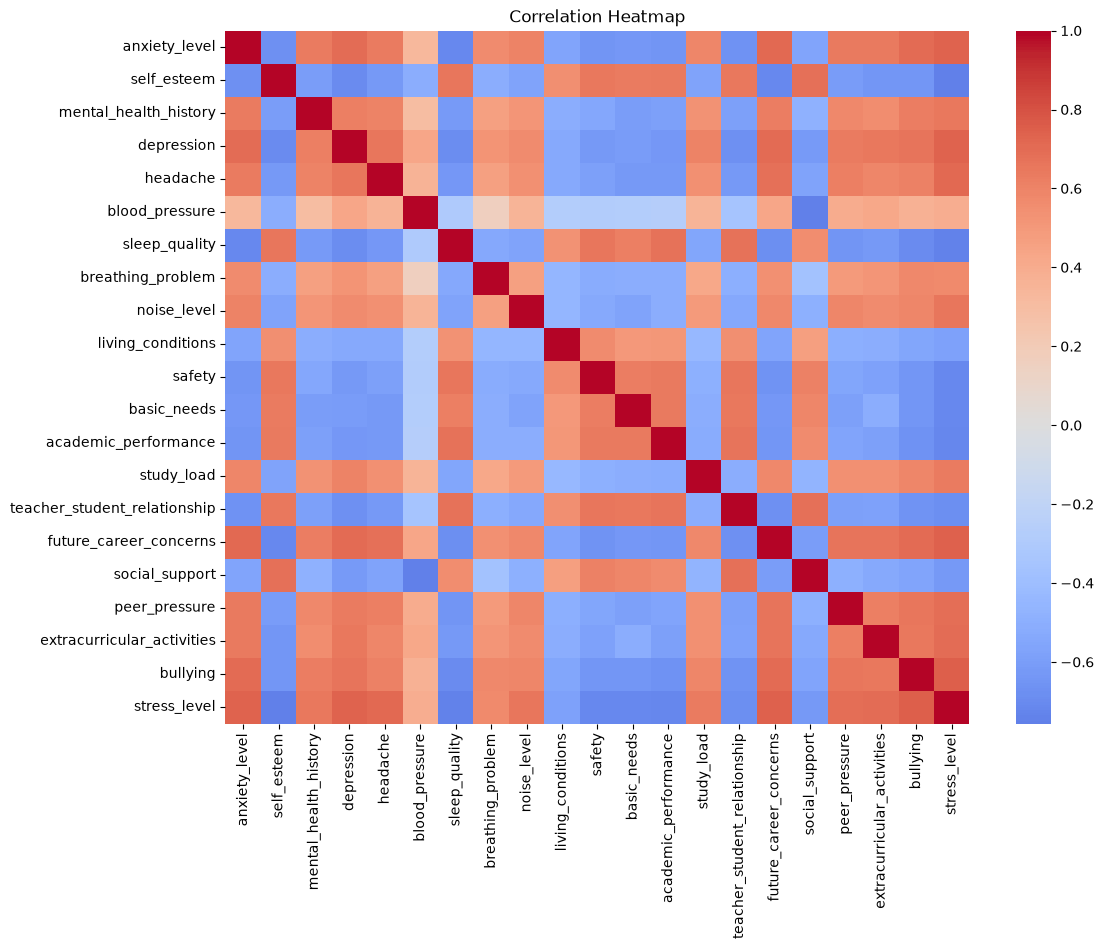

In [19]:
plt.figure(figsize=(12, 9))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

In [21]:
print("Smallest absolute correlation:", round(corr.abs().min(), 2))
print("Largest absolute correlation:", round(corr.abs().max(), 2))
print("extracurricular_activities:", round(corr["extracurricular_activities"], 2))

Smallest absolute correlation: 0.39
Largest absolute correlation: 0.76
extracurricular_activities: 0.69


In [24]:
life_df = pd.read_csv("dataset/student_lifestyle_dataset.csv")
print("Dataset shape:", life_df.shape)
life_df.head()

Dataset shape: (2000, 8)


,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA,Stress_Level
0,1,6.9,3.8,8.7,2.8,1.8,2.99,Moderate
1,2,5.3,3.5,8.0,4.2,3.0,2.75,Low
2,3,5.1,3.9,9.2,1.2,4.6,2.67,Low
3,4,6.5,2.1,7.2,1.7,6.5,2.88,Moderate
4,5,8.1,0.6,6.5,2.2,6.6,3.51,High


In [27]:
print(life_df.info())

<class 'pandas.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 8 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Student_ID                       2000 non-null   int64  
 1   Study_Hours_Per_Day              2000 non-null   float64
 2   Extracurricular_Hours_Per_Day    2000 non-null   float64
 3   Sleep_Hours_Per_Day              2000 non-null   float64
 4   Social_Hours_Per_Day             2000 non-null   float64
 5   Physical_Activity_Hours_Per_Day  2000 non-null   float64
 6   GPA                              2000 non-null   float64
 7   Stress_Level                     2000 non-null   str    
dtypes: float64(6), int64(1), str(1)
memory usage: 125.1 KB
None


In [28]:
life_df.describe()

,Student_ID,Study_Hours_Per_Day,Extracurricular_Hours_Per_Day,Sleep_Hours_Per_Day,Social_Hours_Per_Day,Physical_Activity_Hours_Per_Day,GPA
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000
mean,1000.500000,7.475800,1.990100,7.501250,2.704550,4.32830,3.115960
std,577.494589,1.423888,1.155855,1.460949,1.688514,2.51411,0.298674
min,1.000000,5.000000,0.000000,5.000000,0.000000,0.00000,2.240000
25%,500.750000,6.300000,1.000000,6.200000,1.200000,2.40000,2.900000
50%,1000.500000,7.400000,2.000000,7.500000,2.600000,4.10000,3.110000
75%,1500.250000,8.700000,3.000000,8.800000,4.100000,6.10000,3.330000
max,2000.000000,10.000000,4.000000,10.000000,6.000000,13.00000,4.000000


In [29]:
print(life_df.isnull().sum())
print(life_df["Stress_Level"].value_counts())

Student_ID                         0
Study_Hours_Per_Day                0
Extracurricular_Hours_Per_Day      0
Sleep_Hours_Per_Day                0
Social_Hours_Per_Day               0
Physical_Activity_Hours_Per_Day    0
GPA                                0
Stress_Level                       0
dtype: int64
Stress_Level
High        1029
Moderate     674
Low          297
Name: count, dtype: int64


In [30]:
life_df = life_df.copy()

In [31]:
life_df.columns = life_df.columns.str.strip()

In [32]:
for col in life_df.select_dtypes(include=["object", "string"]).columns:
    life_df[col] = life_df[col].str.strip()

In [33]:
print("Duplicate rows:", life_df.duplicated().sum())

Duplicate rows: 0


In [35]:
ranges = pd.DataFrame({
    "Min": life_df.min(numeric_only=True),
    "Max": life_df.max(numeric_only=True)
})
print(ranges)

                                  Min     Max
Student_ID                       1.00  2000.0
Study_Hours_Per_Day              5.00    10.0
Extracurricular_Hours_Per_Day    0.00     4.0
Sleep_Hours_Per_Day              5.00    10.0
Social_Hours_Per_Day             0.00     6.0
Physical_Activity_Hours_Per_Day  0.00    13.0
GPA                              2.24     4.0


In [36]:
print("Negative values:", (life_df.select_dtypes("number") < 0).sum().sum())
print("GPA range:", life_df["GPA"].min(), "to", life_df["GPA"].max())

Negative values: 0
GPA range: 2.24 to 4.0


In [37]:
hour_cols = [c for c in life_df.columns if c.endswith("Per_Day")]
print("Hour columns:", hour_cols)
total_hours = life_df[hour_cols].sum(axis=1)
print(total_hours.describe())

Hour columns: ['Study_Hours_Per_Day', 'Extracurricular_Hours_Per_Day', 'Sleep_Hours_Per_Day', 'Social_Hours_Per_Day', 'Physical_Activity_Hours_Per_Day']
count    2.000000e+03
mean     2.400000e+01
std      1.575252e-15
min      2.400000e+01
25%      2.400000e+01
50%      2.400000e+01
75%      2.400000e+01
max      2.400000e+01
dtype: float64


In [38]:
print("Rows where total hours are not 24:", ((total_hours - 24).abs() > 1e-6).sum())

Rows where total hours are not 24: 0


In [39]:
num_cols = ["Study_Hours_Per_Day", "Extracurricular_Hours_Per_Day", "Sleep_Hours_Per_Day",
            "Social_Hours_Per_Day", "Physical_Activity_Hours_Per_Day", "GPA"]
outlier_results = []
for col in num_cols:
    q1 = life_df[col].quantile(0.25)
    q3 = life_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (
        (life_df[col] < lower) |
        (life_df[col] > upper)
    ).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))

                         Column  Lower Bound  Upper Bound  Flagged Values
            Study_Hours_Per_Day         2.70        12.30               0
  Extracurricular_Hours_Per_Day        -2.00         6.00               0
            Sleep_Hours_Per_Day         2.30        12.70               0
           Social_Hours_Per_Day        -3.15         8.45               0
Physical_Activity_Hours_Per_Day        -3.15        11.65               5
                            GPA         2.26         3.98               4


In [40]:
def find_col(data, keyword):
    return [c for c in data.columns if keyword.lower() in c.lower()][0]

study = find_col(life_df, "study")
sleep = find_col(life_df, "sleep")
stress = find_col(life_df, "stress")
print("Using columns:", study, sleep, stress)

Using columns: Study_Hours_Per_Day Sleep_Hours_Per_Day Stress_Level


In [46]:
X2 = life_df[[study, sleep]]
y = life_df[stress]
tree = DecisionTreeClassifier(max_depth=3, random_state=42)
scores = cross_val_score(tree, X2, y, cv=5)
print("CV accuracy using only study and sleep hours:", round(scores.mean(), 3))

CV accuracy using only study and sleep hours: 1.0


In [47]:
print(export_text(tree.fit(X2, y), feature_names=list(X2.columns)))

|--- Study_Hours_Per_Day <= 8.05
|   |--- Sleep_Hours_Per_Day <= 5.95
|   |   |--- class: High
|   |--- Sleep_Hours_Per_Day >  5.95
|   |   |--- Study_Hours_Per_Day <= 5.95
|   |   |   |--- class: Low
|   |   |--- Study_Hours_Per_Day >  5.95
|   |   |   |--- class: Moderate
|--- Study_Hours_Per_Day >  8.05
|   |--- class: High



In [48]:
rule = np.where(
    (life_df[study] > 8) | (life_df[sleep] < 6), "High",
    np.where((life_df[sleep] >= 6) & (life_df[study] < 6), "Low", "Moderate")
)
match = (rule == life_df[stress]).mean()
print("Hand written rule matches the label for", round(match * 100, 2), "% of students")

Hand written rule matches the label for 100.0 % of students


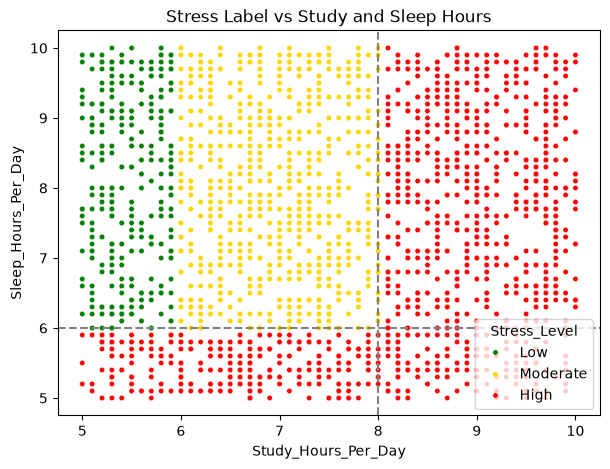

In [49]:
plt.figure(figsize=(7, 5))
sns.scatterplot(x=life_df[study], y=life_df[sleep], hue=life_df[stress],
                hue_order=["Low", "Moderate", "High"],
                palette=["green", "gold", "red"], s=15)
plt.axvline(8, linestyle="--", color="grey")
plt.axhline(6, linestyle="--", color="grey")
plt.title("Stress Label vs Study and Sleep Hours")
plt.show()

the stress level in this dataset is a formula of study and sleep hours (a hand written rule matches every row), and the five daily hour columns add up to exactly 24 for every student. So the data looks generated and the label is not self-reported stress. It is not used to train the model.

In [ ]:
survey_df = pd.read_csv("dataset/Data_cleaned.csv")
print("Dataset shape:", survey_df.shape)
survey_df.head()

In [ ]:
print(survey_df.info())

In [ ]:
survey_df.describe()

In [ ]:
print(survey_df.isnull().sum())
print(survey_df["Current_stress_level"].value_counts().sort_index())

In [ ]:
survey_df = survey_df.copy()

In [ ]:
survey_df.columns = survey_df.columns.str.strip()

In [ ]:
for col in survey_df.select_dtypes(include=["object", "string"]).columns:
    survey_df[col] = survey_df[col].str.strip()

In [ ]:
print("Unique values in each text column:")
for col in survey_df.select_dtypes(include=["object", "string"]).columns:
    print("\n", col)
    print(survey_df[col].value_counts().to_dict())

In [ ]:
print("Duplicate rows:", survey_df.duplicated().sum())

In [ ]:
survey_df = survey_df.drop("Q Number", axis=1)
print("Dataset shape after dropping the ID column:", survey_df.shape)

In [ ]:
ranges = pd.DataFrame({
    "Min": survey_df.min(numeric_only=True),
    "Max": survey_df.max(numeric_only=True)
})
print(ranges)

In [ ]:
print("Negative values:", (survey_df.select_dtypes("number") < 0).sum().sum())
print("Age range:", survey_df["Age"].min(), "to", survey_df["Age"].max())
print("CGPA range:", survey_df["Current_CGPA"].min(), "to", survey_df["Current_CGPA"].max())

In [ ]:
num_cols = ["Age", "Current_CGPA"]
outlier_results = []
for col in num_cols:
    q1 = survey_df[col].quantile(0.25)
    q3 = survey_df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    count = (
        (survey_df[col] < lower) |
        (survey_df[col] > upper)
    ).sum()
    outlier_results.append({
        "Column": col,
        "Lower Bound": round(lower, 2),
        "Upper Bound": round(upper, 2),
        "Flagged Values": int(count)
    })
outlier_df = pd.DataFrame(outlier_results)
print(outlier_df.to_string(index=False))

a few ages are flagged, but the highest age is 35, which is normal for a university student, and CGPA stays in a valid range. Nothing was removed.

In [ ]:
survey_df["stress_group"] = pd.cut(
    survey_df["Current_stress_level"],
    bins=[0, 2, 3, 5],
    labels=["low", "moderate", "high"]
)
survey_df["stress_high"] = (survey_df["Current_stress_level"] >= 4).astype(int)
print(survey_df["stress_group"].value_counts())
print("Share of high stress:", round(survey_df["stress_high"].mean() * 100, 2), "%")

In [ ]:
sns.countplot(x="Current_stress_level", data=survey_df)
plt.title("Self-Reported Stress Level (1 to 5)")
plt.show()

In [ ]:
orders = {
    "Sleep_quality": ["Poor", "Average", "Good"],
    "Average_sleep_duration_per_night": ["<5 hrs", "5-6 hrs", "7-8 hrs", ">8 hrs"],
    "Overwhelmed_by_academic_workload": ["Never", "Rarely", "Sometimes", "Often", "Always"],
    "Hours_spent_daily_on_academic_activities": ["<1 hrs", "1-2 hrs", "2-3 hrs", "3-4 hrs", ">4 hrs"],
    "Difficulty_falling_asleep": ["Never", "Rarely", "Sometimes", "Often", "Almost Always"],
    "Strength_of_social_support": ["Low", "Moderate", "High"],
    "Physical_activity_per_week": ["Low", "Moderate", "High"],
    "Diet_quality": ["Poor", "Average", "Good"],
    "Daytime_sleepiness_during_classes": ["Never", "Rarely", "Often", "Always"],
    "Focus_on_academic_tasks": ["Never", "Rarely", "Sometimes", "Often", "Always"],
}

In [ ]:
unknown = {c: set(survey_df[c].unique()) - set(o) for c, o in orders.items()}
print("Labels not in the order lists:", {c: v for c, v in unknown.items() if v})

In [ ]:
corr_rows = []
for col in ["Age", "Current_CGPA", "Financial_stress_level", "Current_Study_Year", "Depression_level", "Anxiety_level"]:
    rho, p = spearmanr(survey_df[col], survey_df["Current_stress_level"])
    corr_rows.append({"Feature": col, "Spearman rho": round(rho, 3), "p-value": round(p, 3)})
for col, order in orders.items():
    codes = survey_df[col].map({v: i for i, v in enumerate(order)})
    rho, p = spearmanr(codes, survey_df["Current_stress_level"])
    corr_rows.append({"Feature": col, "Spearman rho": round(rho, 3), "p-value": round(p, 3)})
survey_corr = pd.DataFrame(corr_rows).sort_values("Spearman rho")
print(survey_corr.to_string(index=False))

In [ ]:
plt.figure(figsize=(8, 6))
sns.barplot(x="Spearman rho", y="Feature", data=survey_corr, color="steelblue")
plt.axvline(0, color="black")
plt.title("Spearman Correlation with Current Stress Level")
plt.show()

anxiety and depression show almost no relationship with stress (rho close to 0). In student surveys these scores are usually clearly related, so this is a warning about data quality. Only sleep quality shows a modest link with stress.

In [ ]:
survey_lifestyle = list(orders) + [
    "Bedtime_on_regular_nights", "Use_of_electronic_devices_before_bed",
    "Night_time_caffeine_consumption", "Smoking_or_substance_use", "Chronic_illness"
]
survey_extended = survey_lifestyle + ["Current_CGPA", "Financial_stress_level"]
survey_with_mh = survey_extended + ["Depression_level", "Anxiety_level"]
survey_feature_sets = {
    "Lifestyle": survey_lifestyle,
    "Lifestyle + CGPA + Finance": survey_extended,
    "Plus Depression + Anxiety": survey_with_mh
}

In [ ]:
def make_preprocessor(feats):
    ord_cols = [c for c in feats if c in orders]
    cat_cols = [c for c in feats if c not in orders and survey_df[c].dtype not in ["int64", "float64"]]
    num_cols_f = [c for c in feats if c not in ord_cols and c not in cat_cols]
    parts = []
    if ord_cols:
        parts.append(("ord", OrdinalEncoder(categories=[orders[c] for c in ord_cols]), ord_cols))
    if cat_cols:
        parts.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols))
    if num_cols_f:
        parts.append(("num", StandardScaler(), num_cols_f))
    return ColumnTransformer(parts)

In [ ]:
survey_models = {
    "Baseline (random)": DummyClassifier(strategy="stratified", random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, min_samples_leaf=10, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=6, min_samples_leaf=5, class_weight="balanced", random_state=42)
}
survey_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [ ]:
survey_results = []
for target, scoring in [("stress_group", "f1_macro"), ("stress_high", "f1")]:
    for set_name, feats in survey_feature_sets.items():
        all_models = dict(survey_models)
        if target == "stress_high":
            all_models["Always predict high"] = DummyClassifier(strategy="constant", constant=1)
        for name, model in all_models.items():
            pipeline = Pipeline([
                ("preprocessing", make_preprocessor(feats)),
                ("model", model)
            ])
            scores = cross_val_score(pipeline, survey_df[feats], survey_df[target], cv=survey_cv, scoring=scoring)
            survey_results.append({
                "Target": target,
                "Features": set_name,
                "Model": name,
                "F1 (%)": round(scores.mean() * 100, 2)
            })
survey_results_df = pd.DataFrame(survey_results)

In [ ]:
print("3-class target (macro F1):")
print(survey_results_df[survey_results_df["Target"] == "stress_group"].pivot_table(
    index="Features", columns="Model", values="F1 (%)").to_string())

In [ ]:
print("High vs not high (F1 of the high class):")
print(survey_results_df[survey_results_df["Target"] == "stress_high"].pivot_table(
    index="Features", columns="Model", values="F1 (%)").to_string())

the models stay close to the random baseline, and for high vs not high they do not beat always predicting high. This survey is too weak to train the predictor, so it is not used for modeling. The main dataset (Student Stress Factors) is used for the model below.